## Advanced models

In [1]:
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2015-2016
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019


In [3]:
df = engineered_data_frame(data)

/Users/nassimwalha/Desktop/IFT-6758/notebooks/util/engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [4]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020364,R,5,4,Nashville Predators,left,Arizona Coyotes,Shot,Hit,Wrist Shot,...,6,50.0,-78.0,140.527577,43.829214,False,27.149682,0.000000,27.149682,23.421263
1,2015020364,R,12,10,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Wrist Shot,...,29,77.0,69.0,29.120440,13.416408,False,26.565051,0.000000,26.565051,1.004153
2,2015020364,R,13,11,Nashville Predators,left,Arizona Coyotes,Shot,Takeaway,Wrist Shot,...,7,86.0,35.0,51.971146,12.369317,False,-75.963757,0.000000,-75.963757,7.424449
3,2015020364,R,18,17,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Backhand,...,10,82.0,69.0,19.849433,9.899495,False,45.000000,0.000000,45.000000,1.984943
4,2015020364,R,32,31,Nashville Predators,left,Arizona Coyotes,Shot,Blocked Shot,Wrist Shot,...,23,48.0,85.0,37.013511,42.201896,False,-13.706961,0.000000,-13.706961,1.609283
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021002,R,285,284,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,11,47.0,-75.0,122.690668,43.965896,True,17.198541,0.000000,17.198541,11.153697
311102,2018021002,R,286,285,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Backhand,...,8,74.0,-47.0,121.926207,15.132746,True,-7.594643,5.460213,-13.054856,15.240776
311103,2018021002,R,287,286,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,2,78.0,74.0,8.062258,12.083046,True,24.443955,-7.594643,32.038598,4.031129
311104,2018021002,R,292,291,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Takeaway,Backhand,...,43,68.0,-96.0,164.027437,40.816663,False,59.036243,0.000000,59.036243,3.814592


In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from util.metrics_visualization import generate_four_curves

In [6]:
features_columns = ['Period_Time_Seconds', 'Period', 'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                    'Shoot_Type', 'Last_Event_Type', 'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Rebond', 'Delta_Angle', 'Speed',
                    'Powerplay_Since', 'Friendly_Non_Goalies','Opponent_Non_Goalies']
df_features = df[features_columns]
df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df = df_features
df.info()

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_12068/3377483367.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period_Time_Seconds   311106 non-null  int64  
 1   Period                311106 non-null  int64  
 2   X_Coordinate          311088 non-null  float64
 3   Y_Coordinate          311088 non-null  float64
 4   Distance_Net          311086 non-null  float64
 5   Angle                 311085 non-null  float64
 6   Shoot_Type            311068 non-null  object 
 7   Last_Event_Type       311106 non-null  object 
 8   Last_Coordinate_X     306148 non-null  float64
 9   Last_Coordinate_Y     306149 non-null  float64
 10  Time_Between_Events   311106 non-null  int64  
 11  Distance_Last_Event   306133 non-null  float64
 12  Rebond                311106 non-null  bool   
 13  Delta_Angle           311081 non-null  float64
 14  Speed                 306112 non-null  float64
 15  

In [7]:
df = df.dropna()

In [8]:
df["Rebond"] = df["Rebond"].map(lambda x: 1 if x else 0)

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_12068/3740469922.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Rebond"] = df["Rebond"].map(lambda x: 1 if x else 0)


In [9]:
df = df[df.Speed!=np.inf]

In [10]:
df.is_goal.value_counts()

0    273317
1     27173
Name: is_goal, dtype: int64

In [11]:
df

,Period_Time_Seconds,Period,X_Coordinate,Y_Coordinate,Distance_Net,Angle,Shoot_Type,Last_Event_Type,Last_Coordinate_X,Last_Coordinate_Y,Time_Between_Events,Distance_Last_Event,Rebond,Delta_Angle,Speed,Powerplay_Since,Friendly_Non_Goalies,Opponent_Non_Goalies,is_goal
0,36,1,50.0,20.0,43.829214,27.149682,Wrist Shot,Hit,-78.0,-38.0,6,140.527577,0,27.149682,23.421263,0,5,5,0
1,108,1,77.0,6.0,13.416408,26.565051,Wrist Shot,Faceoff,69.0,-22.0,29,29.120440,0,26.565051,1.004153,0,5,5,0
2,115,1,86.0,-12.0,12.369317,-75.963757,Wrist Shot,Takeaway,35.0,-2.0,7,51.971146,0,-75.963757,7.424449,0,5,5,0
3,193,1,82.0,7.0,9.899495,45.000000,Backhand,Faceoff,69.0,22.0,10,19.849433,0,45.000000,1.984943,0,5,5,0
4,309,1,48.0,-10.0,42.201896,-13.706961,Wrist Shot,Blocked Shot,85.0,-11.0,23,37.013511,0,-13.706961,1.609283,0,5,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,1008,3,-47.0,13.0,43.965896,17.198541,Wrist Shot,Shot,75.0,0.0,11,122.690668,1,17.198541,11.153697,0,5,5,0
311102,1016,3,74.0,-2.0,15.132746,-7.594643,Backhand,Shot,-47.0,13.0,8,121.926207,1,-13.054856,15.240776,0,5,5,0
311103,1018,3,78.0,5.0,12.083046,24.443955,Wrist Shot,Shot,74.0,-2.0,2,8.062258,1,32.038598,4.031129,0,5,5,0
311104,1083,3,-68.0,35.0,40.816663,59.036243,Backhand,Takeaway,96.0,32.0,43,164.027437,0,59.036243,3.814592,0,5,5,1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 300490 entries, 0 to 311105
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period_Time_Seconds   300490 non-null  int64  
 1   Period                300490 non-null  int64  
 2   X_Coordinate          300490 non-null  float64
 3   Y_Coordinate          300490 non-null  float64
 4   Distance_Net          300490 non-null  float64
 5   Angle                 300490 non-null  float64
 6   Shoot_Type            300490 non-null  object 
 7   Last_Event_Type       300490 non-null  object 
 8   Last_Coordinate_X     300490 non-null  float64
 9   Last_Coordinate_Y     300490 non-null  float64
 10  Time_Between_Events   300490 non-null  int64  
 11  Distance_Last_Event   300490 non-null  float64
 12  Rebond                300490 non-null  int64  
 13  Delta_Angle           300490 non-null  float64
 14  Speed                 300490 non-null  float64
 15  

In [13]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,:-1], df.iloc[:,-1], test_size = 0.20, random_state=42)

In [14]:
features_to_standardize = ['Period_Time_Seconds',  'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                     'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Delta_Angle', 'Speed',
                    'Powerplay_Since']
features_one_hot = ['Shoot_Type', 'Last_Event_Type']
features_to_keep = ['Period', 'Rebond', 'Friendly_Non_Goalies','Opponent_Non_Goalies']
my_transformer = ColumnTransformer([('standard', StandardScaler(), features_to_standardize),
                                    ('one-hot', OneHotEncoder(), features_one_hot)],
                                   remainder='passthrough')
X_train = my_transformer.fit_transform(X_train)
X_test = my_transformer.transform(X_test)
y_test.reset_index(inplace= True, drop=True)
y_train.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Last_Coordinate_X',
       'standard__Last_Coordinate_Y', 'standard__Time_Between_Events',
       'standard__Distance_Last_Event', 'standard__Delta_Angle',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Blocked Shot',
       'one-hot__Last_Event_Type_Faceoff',
       'one-hot__Last_Event_Type_Giveaway',
       'one-hot__Last_Event_Type_Goal', 'one-hot__Last_Event_Type_Hit',
       'one-hot__Last_Event_Type_Missed Shot',
       'one-hot__Last_Event_Type_Penalty',
       'one-hot__Last_Event_Type_Shot',
       'one-hot__Last_Event_Type

## Model on distance and angle

In [19]:
X_train_angle_and_distance = X_train[:,3:5]
X_test_angle_and_distance = X_test[:,3:5]
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier()#tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train_angle_and_distance, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train_angle_and_distance,y_train),2))
result_xgb = model_xgb.score(X_test_angle_and_distance,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.96


f1 score: 0.0036670333700036676


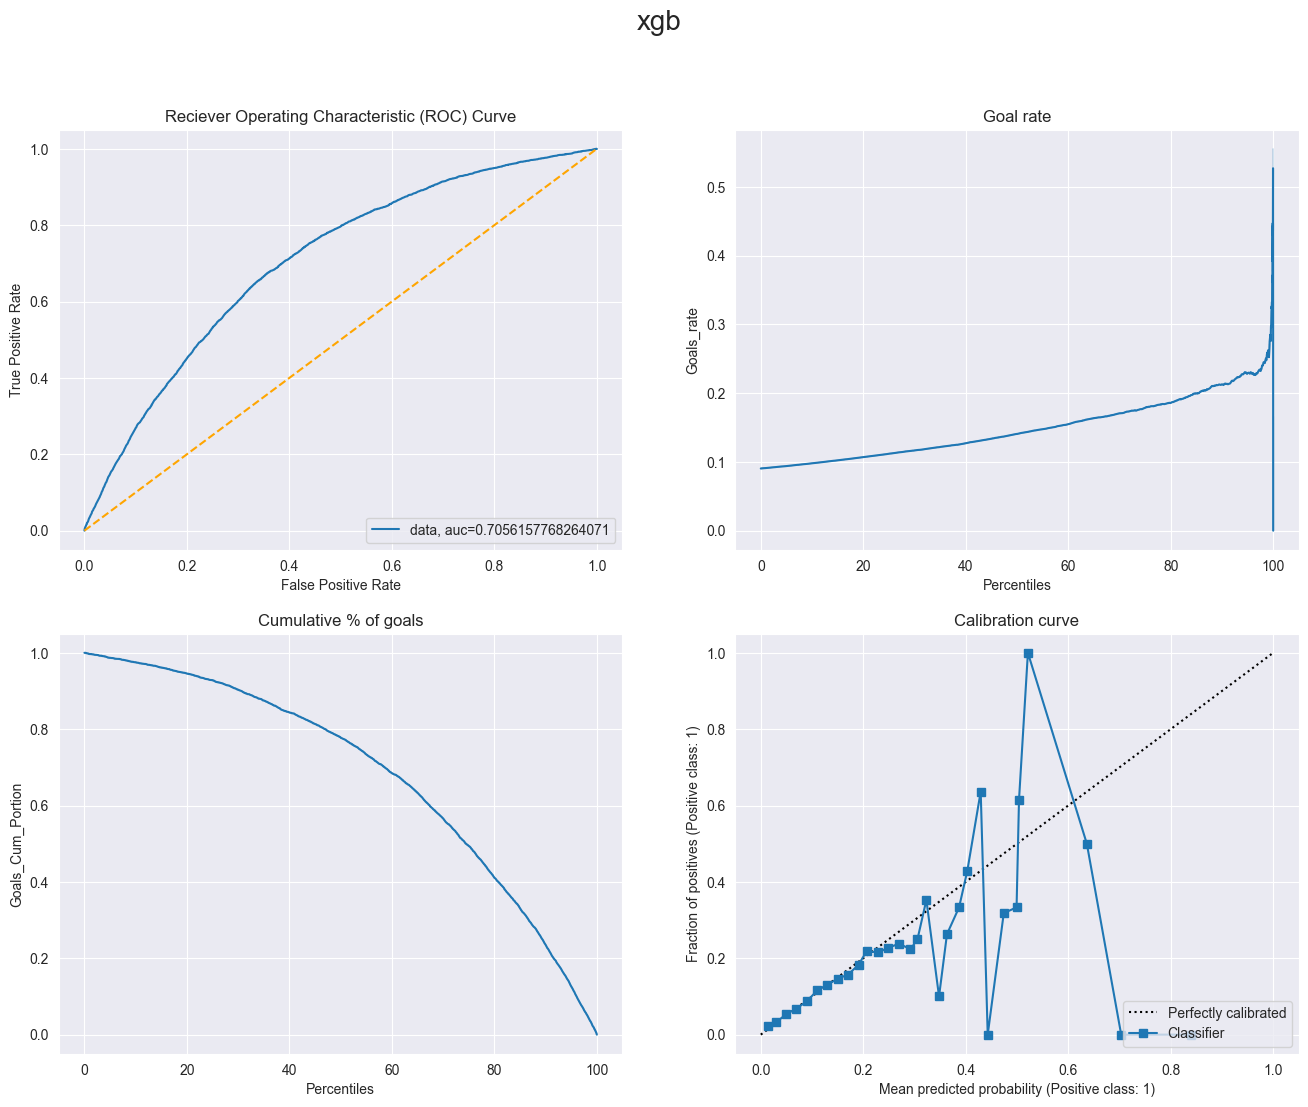

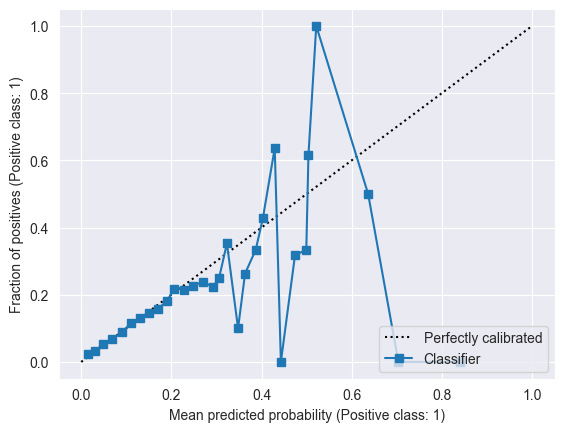

In [22]:
fig = generate_four_curves("xgb_distance_and angle", y_test, classi.predict_proba(X_test_angle_and_distance)[:,1], 50)
f1 = metrics.f1_score(y_test, classi.predict(X_test_angle_and_distance))
print(f"f1 score: {f1}")

### Model on all features + Hyperparameter tuning

In [27]:
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier()#tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train,y_train),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.98


In [ ]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, classi.predict_proba(X_test)[:,1], 50)
f1 = metrics.f1_score(y_test, classi.predict(X_test))
print(f"f1 score: {f1}")

We start tuning our hyperparams

In [ ]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11)
    # 'scale_pos_weight': [0.1, 1.0]
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='f1', cv=5,  #plus iterations, plus chances trouver la bonne combinaison
)
grid_search.fit(X_train, y_train);
print('Finished!')

In [ ]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

In [ ]:
model = grid_search.best_estimator_
model.fit(X_train, y_train)


In [ ]:
# model = xgb.XGBClassifier(tree_method = 'gpu_hist', max_depth = 5, max_delta_step = 2, gamma = 0.16, scale_pos_weight = 0.1)
# model.fit(X_train, y_train)
